# physrisk-lib: a toy demo

[physrisk](https://github.com/os-climate/physrisk) estimates how much damage climate hazards are expected to do to individual physical assets. It chains three steps:

**hazard** (how deep is the 1-in-100-year flood here?) → **vulnerability** (what fraction of the asset does that depth destroy?) → **impact** (expected loss per year, and a risk score)

This notebook runs the real library on real data. It needs internet access but no API key, because the hazard data comes from a public S3 bucket. It takes under a minute to run.

The portfolio is made up: each asset is a hypothetical industrial building at a rough city coordinate, so the results say nothing about any real site.

**Contents:** 1. Hazard lookup · 2. Portfolio impacts · 3. Risk scores · 4. Unpacking one number · 5. Scenarios and time · 6. Your own vulnerability curve · 7. Asset types · 8. Things that could catch you out · 9. Should you use it?

In [1]:
import importlib.metadata
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dependency_injector import providers
from IPython.display import display
from physrisk.container import Container
from physrisk.vulnerability_models.config_based_impact_curves import VulnerabilityConfigItem
from physrisk.vulnerability_models.vulnerability import VulnerabilityModelsFactory

print("physrisk-lib", importlib.metadata.version("physrisk-lib"))

# Container wires the library together; the requester is its main entry point.
# It takes and returns the same JSON as the hosted physrisk API.
requester = Container().requester()

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.bottom": False, "ytick.left": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})


def hazard_curves(lats, lons, hazard, indicator, scenario, year):
    """Raw hazard lookup: one {return period: intensity} dict per location."""
    request = {"items": [{
        "request_item_id": "demo", "latitudes": lats, "longitudes": lons,
        "hazard_type": hazard, "indicator_id": indicator, "scenario": scenario, "year": year,
    }]}
    response = json.loads(requester.get(request_id="get_hazard_data", request_dict=request))
    curves = response["items"][0]["intensity_curve_set"]
    return [dict(zip(c["index_values"], c["intensities"])) for c in curves]


def run_impacts(items, scenario="ssp585", year=2050, requester=requester):
    """Full impact calculation. Results always include the historical baseline too."""
    request = {
        "assets": {"items": items}, "scenario": scenario, "years": [year],
        "include_asset_level": True, "include_calc_details": True, "include_measures": True,
    }
    return json.loads(requester.get(request_id="get_asset_impact", request_dict=request))


def tidy(response, names):
    """Flatten a response to one row per asset, hazard, scenario and impact type."""
    rows = []
    for name, asset in zip(names, response["asset_impacts"]):
        for i in asset["impacts"]:
            rows.append({
                "asset": name, "hazard": i["key"]["hazard_type"], "scenario": i["key"]["scenario_id"],
                "impact_type": i["impact_type"], "aal": i["impact_mean"],
            })
    return pd.DataFrame(rows)


def score_table(response, names):
    """Scores as an asset-by-hazard table, using the labels the response defines."""
    measures = response["risk_measures"]
    definition_set = measures["score_based_measure_set_defn"]
    table = {}
    for m in measures["measures_for_assets"]:
        hazard = m["key"]["hazard_type"]
        # Labels differ between hazard groups, so look them up per hazard and asset.
        # Not every group defines -1, which the other groups label "No vulnerability".
        definition_ids = definition_set["asset_measure_ids_for_hazard"][hazard]
        table[hazard] = [
            {-1: "No vulnerability"} | {v["value"]: v["label"] for v in definition_set["score_definitions"][d]["values"]}
            for d in definition_ids
        ]
        table[hazard] = [labels[score] for labels, score in zip(table[hazard], m["scores"])]
    return pd.DataFrame(table, index=names)


pct = lambda v: f"{v:.3%}"

physrisk-lib 1.10.6


Now the toy portfolio. `asset_class` and `type` choose the vulnerability curve, and `location` selects the regional version of that curve, so it needs to be set correctly (section 8 shows why). The `value_usd_m` column is my own addition, used to turn percentages into dollars. physrisk's calculations work in fractions of asset value and don't use it.

In [2]:
portfolio = pd.DataFrame(
    [
        ("Cologne", 50.94, 6.96, "Europe", 40),
        ("Madrid", 40.42, -3.70, "Europe", 25),
        ("Houston", 29.76, -95.37, "North America", 60),
        ("Tokyo", 35.68, 139.77, "Asia", 80),
        ("Manila", 14.60, 120.98, "Asia", 30),
        ("Barisal", 22.6588, 90.3373, "Asia", 20),
    ],
    columns=["name", "latitude", "longitude", "location", "value_usd_m"],
)


def to_items(df, asset_class="RealEstateAsset", asset_type="Buildings/Industrial"):
    return [
        {"asset_class": asset_class, "type": asset_type, "location": r.location,
         "latitude": r.latitude, "longitude": r.longitude}
        for r in df.itertuples()
    ]


cologne = portfolio[portfolio.name == "Cologne"]
portfolio

,name,latitude,longitude,location,value_usd_m
0,Cologne,50.9400,6.9600,Europe,40
1,Madrid,40.4200,-3.7000,Europe,25
2,Houston,29.7600,-95.3700,North America,60
3,Tokyo,35.6800,139.7700,Asia,80
4,Manila,14.6000,120.9800,Asia,30
5,Barisal,22.6588,90.3373,Asia,20


## 1. Hazard lookup

The rawest thing physrisk does is look up a hazard indicator at a coordinate. Here that's riverine flood depth at the Cologne site, for each return period. The 100-year value is the depth expected to be reached or exceeded with a 1% chance in any year.

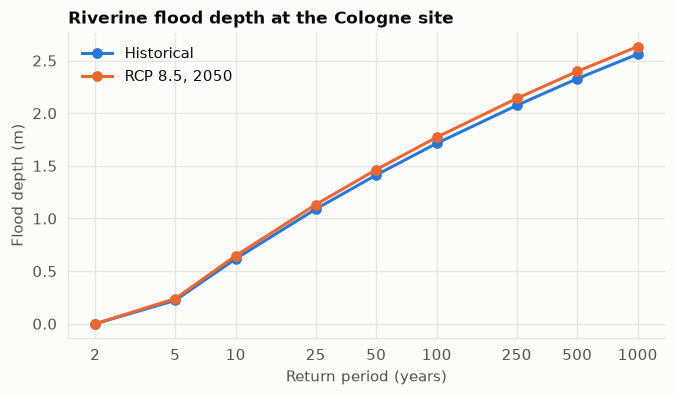

return_period_years,2.0,5.0,10.0,25.0,50.0,100.0,250.0,500.0,1000.0
historical_m,0.0,0.2221,0.6171,1.089,1.413,1.714,2.074,2.328,2.561
rcp85_2050_m,0.0,0.2383,0.6465,1.132,1.464,1.772,2.140,2.397,2.633


In [3]:
lat, lon = [cologne.latitude.iloc[0]], [cologne.longitude.iloc[0]]
baseline = hazard_curves(lat, lon, "RiverineInundation", "flood_depth", "historical", 1980)[0]
future = hazard_curves(lat, lon, "RiverineInundation", "flood_depth", "rcp8p5", 2050)[0]

fig, ax = plt.subplots(figsize=(7, 3.6))
for curve, label, colour in [(baseline, "Historical", SERIES[0]), (future, "RCP 8.5, 2050", SERIES[1])]:
    ax.plot(list(curve), list(curve.values()), marker="o", color=colour, label=label)
ax.set_xscale("log")
ax.set_xticks(list(baseline), [f"{v:g}" for v in baseline])
ax.minorticks_off()
ax.set(title="Riverine flood depth at the Cologne site", xlabel="Return period (years)", ylabel="Flood depth (m)")
ax.legend(loc="upper left")
plt.show()

pd.DataFrame({"historical_m": baseline, "rcp85_2050_m": future}).rename_axis("return_period_years").T

## 2. Portfolio impacts

One request covers every asset and every hazard that has a vulnerability model for that asset type. The main output is **average annual loss (AAL)**, the expected damage per year as a share of asset value.

In [4]:
names = list(portfolio.name)
response = run_impacts(to_items(portfolio), scenario="ssp585", year=2050)
impacts = tidy(response, names)

future_aal = impacts[impacts.scenario == "ssp585"].pivot_table(index="asset", columns="hazard", values="aal").reindex(names)
base_aal = impacts[impacts.scenario == "historical"].pivot_table(index="asset", columns="hazard", values="aal").reindex(names)

summary = future_aal.copy()
summary["Total, SSP5-8.5 2050"] = future_aal.sum(axis=1)
summary["Total, historical"] = base_aal.sum(axis=1)
summary["Toy $m per year"] = summary["Total, SSP5-8.5 2050"] * portfolio.set_index("name").value_usd_m
summary.style.format({c: pct for c in summary.columns if c != "Toy $m per year"} | {"Toy $m per year": "{:.3f}"})

hazard,CoastalInundation,Fire,Hail,RiverineInundation,Wind,"Total, SSP5-8.5 2050","Total, historical",Toy $m per year
asset,,,,,,,,
Cologne,0.000%,0.010%,0.000%,0.377%,0.000%,0.386%,0.327%,0.155
Madrid,0.000%,0.061%,0.000%,0.000%,0.000%,0.061%,0.059%,0.015
Houston,0.000%,0.050%,0.005%,0.029%,0.125%,0.209%,0.297%,0.125
Tokyo,0.000%,0.006%,0.000%,0.000%,0.671%,0.677%,0.305%,0.542
Manila,0.000%,0.026%,0.000%,0.000%,1.189%,1.215%,0.876%,0.364
Barisal,2.528%,0.055%,0.003%,0.000%,0.294%,2.880%,2.150%,0.576


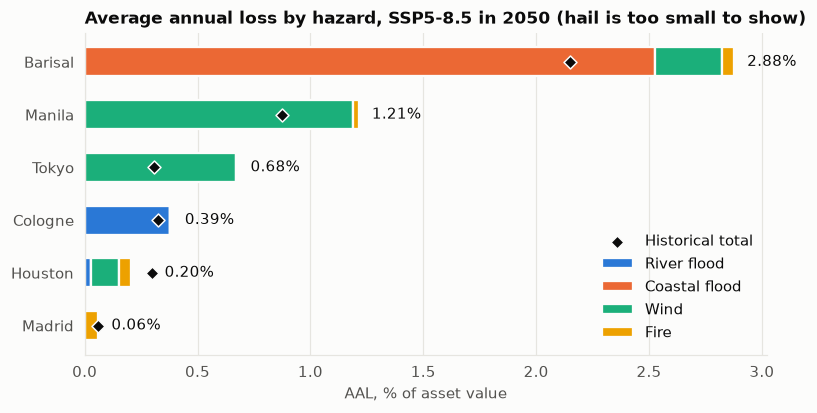

Largest hail AAL in the portfolio: 0.00458%


In [5]:
hazards = {"RiverineInundation": "River flood", "CoastalInundation": "Coastal flood", "Wind": "Wind", "Fire": "Fire"}
order = future_aal.sum(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(order))
for (hazard, label), colour in zip(hazards.items(), SERIES):
    values = future_aal.loc[order, hazard].values * 100
    ax.barh(order, values, left=left, height=0.55, color=colour, edgecolor=SURFACE, linewidth=1.5, label=label)
    left += values
ax.scatter(base_aal.loc[order].sum(axis=1) * 100, order, marker="D", s=36, color=INK, edgecolor=SURFACE,
           linewidth=1, zorder=3, label="Historical total")
for y, (total, past) in enumerate(zip(left, base_aal.loc[order].sum(axis=1) * 100)):
    ax.text(max(total, past) + left.max() * 0.02, y, f"{total:.2f}%", va="center", color=INK)
ax.set(title="Average annual loss by hazard, SSP5-8.5 in 2050 (hail is too small to show)", xlabel="AAL, % of asset value")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

print(f"Largest hail AAL in the portfolio: {future_aal['Hail'].max():.5%}")

## 3. Risk scores

The library also buckets each AAL into a category. Thresholds differ by hazard group and are returned with the response. `No vulnerability` means no model exists for that hazard and asset type, which is different from low risk.

In [6]:
display(score_table(response, names))

definitions = response["risk_measures"]["score_based_measure_set_defn"]["score_definitions"]
flood_defn = next(d for d in definitions.values() if "RiverineInundation" in d["hazard_types"])
pd.DataFrame([
    {"score": v["label"], "AAL from": v["lower_bound"][0], "AAL to": v["upper_bound"][0]}
    for v in flood_defn["values"] if "lower_bound" in v
])

,ChronicHeat,CoastalInundation,Drought,Fire,Hail,PluvialInundation,Precipitation,RiverineInundation,Wind
Cologne,No vulnerability,Very low impact,No vulnerability,Very low impact,Very low impact,No hazard data,No vulnerability,Medium impact,Very low impact
Madrid,No vulnerability,Very low impact,No vulnerability,Low impact,Very low impact,No hazard data,No vulnerability,Very low impact,Very low impact
Houston,No vulnerability,Very low impact,No vulnerability,Low impact,Very low impact,No hazard data,No vulnerability,Low impact,Low impact
Tokyo,No vulnerability,Very low impact,No vulnerability,Very low impact,Very low impact,No hazard data,No vulnerability,Very low impact,Medium impact
Manila,No vulnerability,Very low impact,No vulnerability,Low impact,Very low impact,No hazard data,No vulnerability,Very low impact,High impact
Barisal,No vulnerability,High impact,No vulnerability,Low impact,Very low impact,No hazard data,No vulnerability,Very low impact,Medium impact


,score,AAL from,AAL to
0,Very low impact,-inf,0.0001
1,Low impact,0.0001,0.002
2,Medium impact,0.002,0.01
3,High impact,0.01,0.05
4,Very high impact,0.05,inf


## 4. Unpacking one number

To check this isn't a black box, here is Cologne's river flood AAL rebuilt by hand, using the depth curve from section 1 and the library's vulnerability curve.

In [7]:
cologne_response = run_impacts(to_items(cologne), scenario="ssp585", year=2050)
record = next(
    i for i in cologne_response["asset_impacts"][0]["impacts"]
    if i["key"]["hazard_type"] == "RiverineInundation" and i["key"]["scenario_id"] == "historical"
)
details = record["calc_details"]
print("Data sets used:", *details["hazard_path"], sep="\n  ")

config = VulnerabilityModelsFactory.embedded_vulnerability_config()
curve = next(
    c for c in config
    if c.hazard_class == "RiverineInundation" and c.asset_class == "RealEstateAsset"
    and c.asset_identifier == "type=Buildings/Industrial,location=Europe"
)

# Check 1: looking up each hazard depth on the curve gives the reported damages.
depths = np.array(details["hazard_exceedance"]["values"])
damages = np.array(record["impact_exceedance"]["values"])
by_hand = np.interp(depths, curve.points_x, curve.points_y)
assert np.allclose(by_hand, damages, atol=1e-3)

# Check 2: probability times mid-bin damage, summed, gives the reported AAL.
dist = record["impact_distribution"]
edges, probs = np.array(dist["bin_edges"]), np.array(dist["probabilities"])
aal_by_hand = (probs * (edges[:-1] + edges[1:]) / 2).sum()
assert np.isclose(aal_by_hand, record["impact_mean"], rtol=0.01)

print(f"\nReported AAL {record['impact_mean']:.4%}, rebuilt by hand {aal_by_hand:.4%}")
pd.DataFrame({
    "annual_exceedance_prob": details["hazard_exceedance"]["exceed_probabilities"],
    "flood_depth_m": depths, "damage_reported": damages, "damage_by_hand": by_hand.round(4),
})

Data sets used:
  inundation/wri/v2/inunriver_{scenario}_MIROC-ESM-CHEM_{year}
  inundation/wri/v2/inunriver_{scenario}_MIROC-ESM-CHEM_{year}
  inundation/flopros_riverine/v1/flood_sop/sop



Reported AAL 0.3172%, rebuilt by hand 0.3172%


,annual_exceedance_prob,flood_depth_m,damage_reported,damage_by_hand
0,0.010,1.714,0.2708,0.2708
1,0.004,2.074,0.3200,0.3200
2,0.002,2.328,0.3474,0.3474
3,0.001,2.561,0.3726,0.3726
4,0.000,2.561,0.3726,0.3726


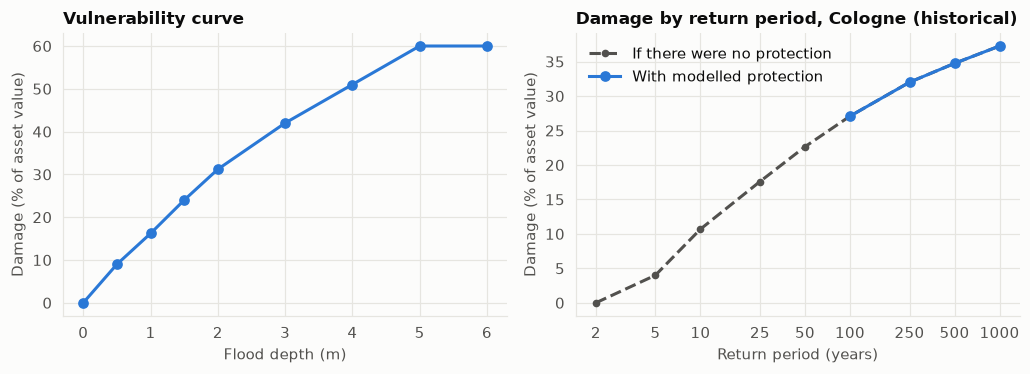

In [8]:
fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(9.5, 3.5))

left_ax.plot(curve.points_x, np.array(curve.points_y) * 100, color=SERIES[0], marker="o")
left_ax.set(title="Vulnerability curve", xlabel="Flood depth (m)", ylabel="Damage (% of asset value)")

probs_exceed = np.array(record["impact_exceedance"]["exceed_probabilities"])
keep = probs_exceed > 0
right_ax.plot(list(baseline), np.interp(list(baseline.values()), curve.points_x, curve.points_y) * 100,
              color=MUTED, linestyle="--", marker="o", markersize=4, label="If there were no protection")
right_ax.plot(1 / probs_exceed[keep], damages[keep] * 100, color=SERIES[0], marker="o", label="With modelled protection")
right_ax.set_xscale("log")
right_ax.set_xticks(list(baseline), [f"{v:g}" for v in baseline])
right_ax.minorticks_off()
right_ax.set(title="Damage by return period, Cologne (historical)", xlabel="Return period (years)", ylabel="Damage (% of asset value)")
right_ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

The right-hand chart shows something a plain depth-to-damage lookup would miss. The `flopros` data set in the paths above supplies an assumed **flood-protection standard**, and the model counts no damage from floods below it. Here, damage starts at the 100-year event, so frequent floods contribute nothing to the AAL even though the raw data shows water at the site. This assumption has a large effect on the answer, and your site's real defences may be very different.

## 5. Scenarios and time

Change `scenario` and `year` and re-run. The dashed line is the historical baseline.

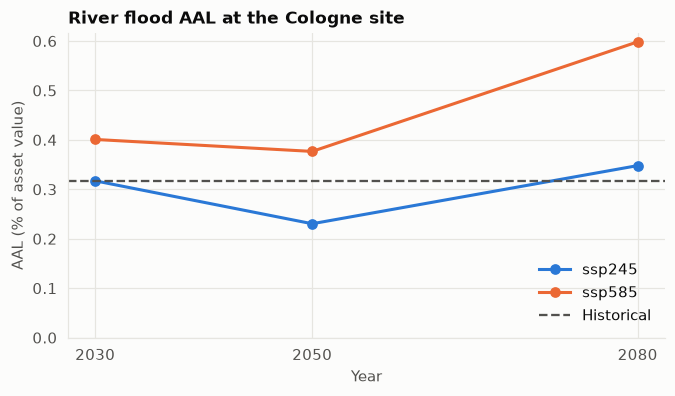

scenario,historical,ssp585
asset,,
Cologne,0.317%,0.377%
Houston,0.162%,0.029%


In [9]:
rows = []
for scenario in ["ssp245", "ssp585"]:
    for year in [2030, 2050, 2080]:
        frame = tidy(run_impacts(to_items(cologne), scenario=scenario, year=year), ["Cologne"])
        river = frame[(frame.hazard == "RiverineInundation") & (frame.scenario == scenario)]
        rows.append({"scenario": scenario, "year": year, "aal": river.aal.iloc[0]})
trajectory = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 3.6))
for (scenario, group), colour in zip(trajectory.groupby("scenario"), SERIES):
    ax.plot(group.year, group.aal * 100, marker="o", color=colour, label=scenario)
ax.axhline(record["impact_mean"] * 100, color=MUTED, linestyle="--", linewidth=1.5, label="Historical")
ax.set_xticks([2030, 2050, 2080])
ax.set_ylim(bottom=0)
ax.set(title="River flood AAL at the Cologne site", xlabel="Year", ylabel="AAL (% of asset value)")
ax.legend(loc="lower right")
plt.show()

river = impacts[impacts.hazard == "RiverineInundation"].pivot_table(index="asset", columns="scenario", values="aal")
display(river.loc[["Cologne", "Houston"]].style.format(pct))

Be careful reading these lines as a trend. The paths in section 4 show the river flood projection comes from a **single climate model** (`MIROC-ESM-CHEM`), so the ups and downs between years are probably model noise as much as signal. The table shows the same thing another way: under the same scenario, one site's flood risk goes up and the other's goes down. There's no multi-model range to show how uncertain this is.

## 6. Your own vulnerability curve

This is one of the library's main selling points: curves are just configuration, so you can swap in your own. Here's a what-if for Cologne: raise the building on a 1 m plinth by shifting the curve 1 m to the right. Note that a custom config **replaces** the default set, so only the hazards you define come back.

In [10]:
plinth_item = VulnerabilityConfigItem(
    hazard_class="RiverineInundation",
    asset_class="RealEstateAsset",
    asset_identifier="type=Buildings/Industrial,location=Europe",
    indicator_id=curve.indicator_id,
    indicator_units=curve.indicator_units,
    impact_id=curve.impact_id,
    impact_units=None,
    curve_type=curve.curve_type,
    points_x=[x + 1 for x in curve.points_x],
    points_y=list(curve.points_y),
    activation_of_points_x=None,
    cap_of_points_x=None,
    cap_of_points_y=None,
)

container = Container()
container.override_providers(
    vulnerability_models_factory=providers.Factory(VulnerabilityModelsFactory, config=[plinth_item])
)
plinth = tidy(run_impacts(to_items(cologne), requester=container.requester()), ["Cologne"])

standard = tidy(cologne_response, ["Cologne"])
pick = lambda frame: frame[(frame.hazard == "RiverineInundation") & (frame.scenario == "ssp585")].aal.iloc[0]
before, after = pick(standard), pick(plinth)
print(f"River flood AAL, SSP5-8.5 2050: {before:.3%} -> {after:.3%} ({after / before - 1:+.0%})")
print("Hazards returned with the custom config:", sorted(plinth.hazard.unique()))

River flood AAL, SSP5-8.5 2050: 0.377% -> 0.208% (-45%)
Hazards returned with the custom config: ['RiverineInundation']


## 7. Asset types

Other asset classes bring different hazards and a second impact type, `disruption` (lost output rather than physical damage). Here's the same Cologne coordinate modelled as three kinds of asset.

In [11]:
variants = {
    "Industrial building": ("RealEstateAsset", "Buildings/Industrial"),
    "Generic manufacturing": ("ManufacturingAsset", "Generic"),
    "Gas power plant": ("ThermalPowerGeneratingAsset", "Gas"),
}
frames = []
for label, (asset_class, asset_type) in variants.items():
    frame = tidy(run_impacts(to_items(cologne, asset_class, asset_type)), [label])
    frames.append(frame[frame.scenario == "ssp585"])
(
    pd.concat(frames)
    .pivot_table(index=["hazard", "impact_type"], columns="asset", values="aal")[list(variants)]
    .style.format(pct, na_rep="not modelled")
)

## 8. Things that could catch you out

I found these while building the demo, and each one is re-run live below. None of them raises an error, so they could easily slip through in real use.

### a) A wrong `location` is silently accepted and changes the answer

The `Nonsense` figure is identical to generic manufacturing in section 7, which suggests an unrecognised location falls back to a generic curve.

In [12]:
locations = ["Europe", "North America", "Asia", "Global", "Nonsense"]
frame = tidy(run_impacts(to_items(pd.concat([cologne] * 5).assign(location=locations))), locations)
frame[(frame.hazard == "RiverineInundation") & (frame.scenario == "ssp585")].set_index("asset")[["aal"]].style.format(pct)

,aal
asset,
Europe,0.377%
North America,0.528%
Asia,0.517%
Global,0.499%
Nonsense,0.433%


### b) Results depend on the exact pixel

Each number below is the 100-year flood depth in metres, looked up on a grid around the Cologne site with steps of about 1 km. The centre cell is the site. You need accurate coordinates: a city-centre geocode, or even a rough address, can land in a very different cell. It's also why several sites above show zero river flood, which only means that exact point is dry in the data, not that the city has no flood risk.

In [13]:
steps = [-0.02, -0.01, 0.0, 0.01, 0.02]
lat0, lon0 = cologne.latitude.iloc[0], cologne.longitude.iloc[0]
points = [(lat0 + dy, lon0 + dx) for dy in steps[::-1] for dx in steps]
curves = hazard_curves([p[0] for p in points], [p[1] for p in points], "RiverineInundation", "flood_depth", "historical", 1980)

grid = pd.DataFrame(
    np.array([c[100.0] for c in curves]).reshape(5, 5),
    index=[f"{dy:+.2f}° lat" for dy in steps[::-1]],
    columns=[f"{dx:+.2f}° lon" for dx in steps],
)
grid.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0)

,-0.02° lon,-0.01° lon,+0.00° lon,+0.01° lon,+0.02° lon
+0.02° lat,0.00,0.00,0.00,0.00,0.00
+0.01° lat,0.00,0.00,0.00,2.24,0.00
+0.00° lat,0.00,0.00,1.71,2.24,0.00
-0.01° lat,0.00,0.00,0.00,2.24,0.00
-0.02° lat,0.00,0.00,0.00,1.40,2.24


### c) "Very low" can mean "no data"

Here's an asset in the middle of the Atlantic Ocean. It should be flagged as a bad coordinate, but flood comes back as `Very low impact` rather than `No hazard data`, so **a bad geocode looks like a safe asset**. The `PluvialInundation` row shows what the real no-data label looks like. Pluvial (surface water) flood also returned no data for every site in the portfolio above, so this setup doesn't appear to cover it at all. Validate your coordinates before you trust a low score. Tropical cyclone wind does have data out at sea, which is why that row isn't very low.

In [14]:
ocean = pd.DataFrame([{"name": "Mid-Atlantic", "latitude": 30.0, "longitude": -40.0, "location": "Global"}])
ocean_response = run_impacts(to_items(ocean))
print("Raw 100-year flood lookup:", hazard_curves([30.0], [-40.0], "RiverineInundation", "flood_depth", "historical", 1980)[0])
score_table(ocean_response, ["Mid-Atlantic"]).T

Raw 100-year flood lookup: {100.0: 0.0}


,Mid-Atlantic
ChronicHeat,No vulnerability
CoastalInundation,Very low impact
Drought,No vulnerability
Fire,Very low impact
Hail,Very low impact
PluvialInundation,No hazard data
Precipitation,No vulnerability
RiverineInundation,Very low impact
Wind,Low impact


### d) Scenarios can silently drop hazards

Not every hazard has data for every scenario. Ask for one that isn't covered and you get fewer results, or none, with no warning. If you compare scenarios by summing hazards, you'd be comparing different sets of hazards.

In [15]:
coverage = {}
for scenario in ["ssp126", "ssp245", "ssp370", "ssp585"]:
    frame = tidy(run_impacts(to_items(cologne), scenario=scenario, year=2050), ["Cologne"])
    returned = set(frame[frame.scenario == scenario].hazard)
    coverage[scenario] = {h: "yes" if h in returned else "-" for h in ["RiverineInundation", "CoastalInundation", "Wind", "Fire", "Hail"]}
pd.DataFrame(coverage)

,ssp126,ssp245,ssp370,ssp585
RiverineInundation,-,yes,-,yes
CoastalInundation,-,yes,-,yes
Wind,-,yes,-,yes
Fire,yes,-,-,yes
Hail,yes,-,-,yes


### e) Zero wind may just mean "no cyclones"

Wind at this Cologne site comes from `wind/iris`, a tropical cyclone model, so Europe shows zero wind. That means no cyclones, not no wind risk: European windstorms don't appear to be covered by the data the default setup used here.

In [16]:
wind = next(i for i in cologne_response["asset_impacts"][0]["impacts"] if i["key"]["hazard_type"] == "Wind")
print(wind["calc_details"]["hazard_path"], "| AAL:", wind["impact_mean"])

['wind/iris/v1/max_speed_{scenario}_{year}'] | AAL: 0.0


## 9. Should you use it?

**It's a good fit if** you want a transparent, free, scriptable way to screen many assets across hazards and test assumptions. Every number here could be traced and rebuilt by hand, curves are easy to replace, and setup took one install with no credentials.

**Treat it with care if** you need decision-grade numbers for individual sites. The defaults rest on a global flood-protection data set, ~1 km pixels and, for river flood, a single climate model. It also doesn't guard against bad input, so you'd want your own checks on coordinates, `location` values and scenario coverage. The library has more depth than this demo covers (portfolio-level modelling, commercial data sources, and hosting it as an API).

**To try it on your own assets,** edit the `portfolio` table in the setup section and choose the matching `asset_class` and `type`, then re-run. Try real site coordinates, not city centres.

Further reading: [documentation](https://physrisk.readthedocs.io/en/latest/) · [source](https://github.com/os-climate/physrisk) · [hazard data registry](https://registry.opendata.aws/os-climate-physrisk/).